# 04 &nbsp;What does each option cost per 1,000 requests, and how fast is it?

**The problem.** Accuracy is half the decision. A hosted model is paid per request and answers over the network; a self-hosted small model costs a fixed amount for a server and answers locally. A team needs both on the same scale: dollars per 1,000 requests, and time per answer.

**The approach.**

1. Cost the hosted models from what they actually used. Every API answer was saved with its token counts, so cost is computed from real usage, not estimates, at Anthropic's published prices.
2. Show where that cost comes from, and what prompt caching and the Batch API change.
3. Cost the self-hosted model as a small cloud server, and turn that into a cost per 1,000 requests at different monthly volumes.
4. Compare speed: the time to answer one message.

Labelling and training costs, and what a wrong answer costs, come in notebook 05, where they decide the break-even volume.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fopstudy import plots, prompting, style
from fopstudy.costs import (BATCH_DISCOUNT, PRICES, PRICES_CHECKED, SERVER_CHECKED, SERVER_NAME,
                            SERVER_PER_HOUR, request_cost, server_capacity, server_monthly_cost)
from fopstudy.results import RESULTS_DIR, correctness

style.use_style()
runs = pd.read_csv(RESULTS_DIR / "runs_api.csv").set_index("run")
records = {run: pd.DataFrame(prompting.read_records(prompting.API_DIR / f"{run}.jsonl")) for run in runs.index}
local_ms = pd.read_csv(RESULTS_DIR / "latency_local.csv")

def name(run):
    model, k = run.split("_shots") if "_shots" in run else run.split("_retrieved")
    if "_retrieved" in run:
        return f"{model.capitalize()}, {k} retrieved examples per message"
    return f"{model.capitalize()}, {k} example{'s' if k != '1' else ''} per intent"

def approach_and_size(run):  # where a run's predictions are saved
    return (run, "all") if runs.loc[run, "retrieved"] else (run.split("_")[0], int(runs.loc[run, "shots"]))

print(f"API prices checked {PRICES_CHECKED}; server price checked {SERVER_CHECKED}.")
pd.DataFrame({m.capitalize(): vars(p) for m, p in PRICES.items()}).T.rename(
    columns=lambda c: f"{c.replace('_', ' ')} ($ per million tokens)")

API prices checked 2026-11-15; server price checked 2026-11-17.


,input ($ per million tokens),output ($ per million tokens),cache write ($ per million tokens),cache read ($ per million tokens)
Haiku,0.1,0.5,0.125,0.01
Sonnet,2.0,10.0,2.500,0.10


## 1. What one hosted request uses

Every request sends the same long system prompt (the 77 intent names, plus any examples) and one short customer message, and gets back a short JSON answer naming one intent. The system prompt was cached: after the first request, it is read from the cache at a tenth of the normal input price.

Two runs work differently (notebook 02, section 7): each request carries the 10 labelled training messages most similar to the customer's message. Those examples change with every message, so they are paid at the full input price; only the instructions and the intent list are cached.

In [2]:
usage = pd.DataFrame({
    "Requests": runs["requests"],
    "Prompt read from cache (tokens)": runs["cache_read_tokens_mean"].round(0),
    "New input (tokens)": runs["input_tokens_mean"].round(0),
    "Output (tokens)": runs["output_tokens_mean"].round(0),
    "Requests served from cache": runs["cache_hit_share"],
    "Cost per 1,000 requests ($)": runs["cost_per_1k"],
}, index=runs.index).rename(index=name).rename_axis("Option")
usage.style.format({"Requests": "{:,.0f}", "Prompt read from cache (tokens)": "{:,.0f}", "New input (tokens)": "{:.0f}",
                    "Output (tokens)": "{:.0f}", "Requests served from cache": "{:.1%}",
                    "Cost per 1,000 requests ($)": "{:.3f}"})

,Requests,Prompt read from cache (tokens),New input (tokens),Output (tokens),Requests served from cache,"Cost per 1,000 requests ($)"
Option,,,,,,
"Haiku, 0 examples per intent","3,080","1,962",28,17,100.0%,0.031
"Haiku, 1 example per intent","3,080","4,217",28,17,100.0%,0.054
"Haiku, 5 examples per intent","3,080","10,129",28,17,100.0%,0.113
"Sonnet, 0 examples per intent","1,540","1,962",28,17,99.9%,0.427
"Sonnet, 1 example per intent","1,540","4,215",28,17,99.9%,0.657
"Sonnet, 5 examples per intent","1,540","10,119",28,17,99.9%,1.274
"Haiku, 10 retrieved examples per message","1,540","1,962",329,17,99.9%,0.061
"Sonnet, 10 retrieved examples per message","1,540","1,962",329,17,99.9%,1.032


## 2. What caching and batching change

The same requests, priced three ways: as run (with the prompt cached), as if nothing were cached, and through the Batch API, which halves every price but returns answers within hours instead of a second, so it suits overnight jobs, not live customers.

In [3]:
def priced(df, cache=True, batch=False):
    price = PRICES[df["model_key"].iloc[0]]
    if cache:
        cost = [request_cost(price, r.input_tokens, r.output_tokens, r.cache_read_tokens, r.cache_write_tokens, batch)
                for r in df.itertuples()]
    else:
        cost = [request_cost(price, r.input_tokens + r.cache_read_tokens + r.cache_write_tokens, r.output_tokens,
                             batch=batch) for r in df.itertuples()]
    return 1000 * float(np.mean(cost))

cost = pd.DataFrame({
    "No caching": {run: priced(df, cache=False) for run, df in records.items()},
    "With caching (as run)": {run: priced(df) for run, df in records.items()},
    "Caching and Batch API": {run: priced(df, batch=True) for run, df in records.items()},
})
cost["Saved by caching"] = 1 - cost["With caching (as run)"] / cost["No caching"]
cost.index = cost.index.map(name)
cost.index.name = "Cost per 1,000 requests ($)"
cost.style.format({c: "{:.3f}" for c in cost.columns[:3]} | {"Saved by caching": "{:.0%}"})

,No caching,With caching (as run),Caching and Batch API,Saved by caching
"Cost per 1,000 requests ($)",,,,
"Haiku, 0 examples per intent",0.208,0.031,0.016,85%
"Haiku, 1 example per intent",0.433,0.054,0.027,88%
"Haiku, 5 examples per intent",1.025,0.113,0.057,89%
"Sonnet, 0 examples per intent",4.154,0.427,0.214,90%
"Sonnet, 1 example per intent",8.665,0.657,0.328,92%
"Sonnet, 5 examples per intent",20.493,1.274,0.637,94%
"Haiku, 10 retrieved examples per message",0.238,0.061,0.031,74%
"Sonnet, 10 retrieved examples per message",4.759,1.032,0.516,78%


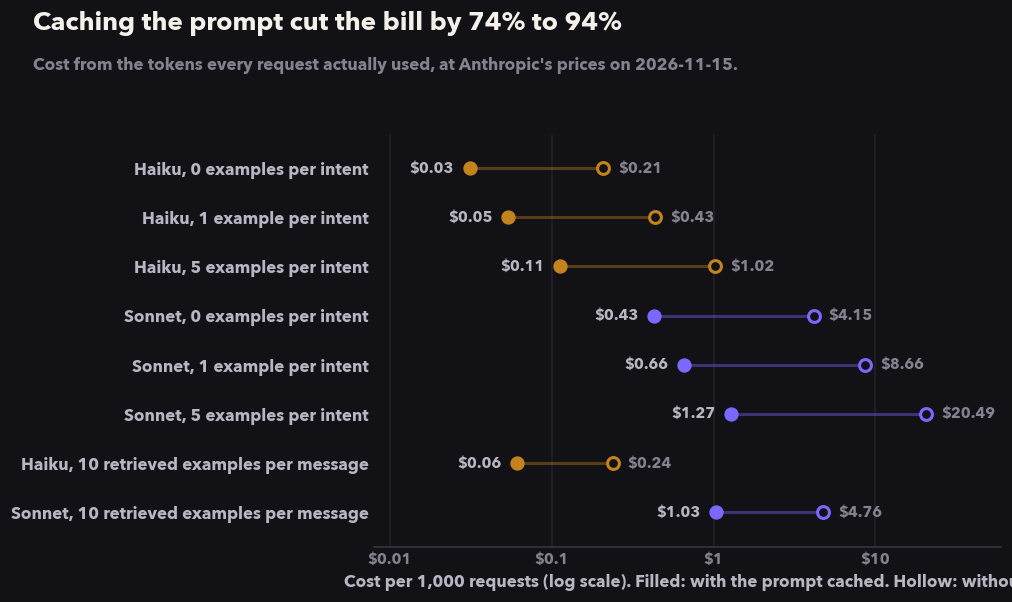

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.6))
y = np.arange(len(cost))[::-1]
for yi, (label, r) in zip(y, cost.iterrows()):
    colour = style.APPROACH_COLORS[label.split(",")[0].lower()]
    ax.plot([r["With caching (as run)"], r["No caching"]], [yi, yi], color=colour, linewidth=2, alpha=0.4)
    ax.scatter(r["No caching"], yi, s=60, facecolor=style.SURFACE, edgecolor=colour, linewidth=2, zorder=3)
    ax.scatter(r["With caching (as run)"], yi, s=70, color=colour, zorder=3)
    ax.annotate(f"${r['With caching (as run)']:.2f}", (r["With caching (as run)"], yi), xytext=(-10, 0),
                textcoords="offset points", ha="right", va="center", color=style.INK_2, fontsize=10)
    ax.annotate(f"${r['No caching']:.2f}", (r["No caching"], yi), xytext=(10, 0),
                textcoords="offset points", va="center", color=style.MUTED, fontsize=10)
ax.set_xscale("log")
ax.set_xticks([0.01, 0.1, 1, 10])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:g}"))
ax.minorticks_off()
ax.set_xlim(0.008, 60)
ax.set_yticks(y)
ax.set_yticklabels(cost.index)
ax.set_ylim(-0.7, len(cost) - 0.3)
ax.set_xlabel("Cost per 1,000 requests (log scale). Filled: with the prompt cached. Hollow: without.")
fig.subplots_adjust(top=0.78, left=0.33)
saved = cost["Saved by caching"]
style.headline(fig, f"Caching the prompt cut the bill by {saved.min():.0%} to {saved.max():.0%}",
               f"Cost from the tokens every request actually used, at Anthropic's prices on {PRICES_CHECKED}.")
style.save(fig, "api_cost_caching")

Caching matters more as the prompt grows: with five examples per intent the prompt is about 10,000 tokens, and without caching Sonnet would cost about \$20 per 1,000 requests instead of about \$1.30. Even with caching, the examples are not free: five per intent makes each request three to four times dearer than none, because the cached prompt is still read, at a tenth of the price, on every request.

Retrieved examples are the exception. Only the intent list is cached, so caching saves less, but the request is still cheaper than a prompt with five fixed examples of every intent: ten examples chosen for the message are far fewer tokens than 385 chosen in advance.

Output is a small share of the cost because each answer is about 17 tokens: a short JSON object naming one intent.

## 3. What the self-hosted model costs

The small models run on a CPU, one message at a time, so the cheapest realistic home for them is a small cloud server running all month. The price used here is an AWS c7g.large (2 vCPUs, 4 GB of memory), on demand in the us-east-1 region. The server costs the same whether it answers ten requests or ten million, so its cost per 1,000 requests depends on the volume.

Speeds were measured on an Apple M4 laptop CPU limited to 2 threads. A cloud server's cores are slower, so capacity below assumes it runs **3 times slower** and is kept only **half busy**, leaving room for traffic peaks. Both are cautious guesses; even so, one server has capacity to spare at any volume considered here.

In [5]:
server = server_monthly_cost()
speed = local_ms.groupby("approach")["ms"].median()
capacity = pd.DataFrame({
    "Median time on the laptop (ms)": speed,
    "Requests a month, one server (cautious)": [server_capacity(ms, slowdown=3, utilisation=0.5) for ms in speed],
}).rename(index=style.APPROACH_LABELS).rename_axis("Model")
print(f"{SERVER_NAME}: ${SERVER_PER_HOUR} an hour, ${server:.2f} a month, checked {SERVER_CHECKED}.")
capacity.style.format({"Median time on the laptop (ms)": "{:.1f}", "Requests a month, one server (cautious)": "{:,.0f}"})

AWS c7g.large (2 vCPUs): $0.0725 an hour, $52.92 a month, checked 2026-11-17.


,Median time on the laptop (ms),"Requests a month, one server (cautious)"
Model,,
"Small model, fine-tuned",15.4,"28,487,805"
"Small model, not fine-tuned",4.5,"96,795,580"


In [6]:
volumes = [100_000, 1_000_000, 10_000_000]
per_1k = pd.DataFrame({f"{v:,} requests a month": [1000 * server / v] for v in volumes},
                      index=["Self-hosted, either small model ($ per 1,000)"])
per_1k.style.format("{:.3f}")

,"100,000 requests a month","1,000,000 requests a month","10,000,000 requests a month"
"Self-hosted, either small model ($ per 1,000)",0.529,0.053,0.005


A self-hosted model at 100,000 requests a month costs about as much per request as Sonnet; at a million a month, about as much as Haiku with one example; at ten million, a fraction of a cent per 1,000. That is the shape of the decision in notebook 05: a flat price per request against a fixed bill spread over the volume.

## 4. How fast each option answers

For the hosted models, the time is from sending a request to receiving the answer, measured from a home internet connection with four requests in flight, so it includes the network. For the small models, it is the model alone on the laptop CPU (2 threads), one message at a time; a deployed model would add its own network hop of a few to tens of milliseconds.

,Median (ms),5th percentile (ms),95th percentile (ms)
Option,,,
"Not fine-tuned, local CPU",4.5,4.1,5.4
"Fine-tuned, local CPU",15.4,14.7,18.6
"Haiku, 0 examples per intent",797.3,727.9,"1,049.8"
"Haiku, 1 example per intent",764.4,682.3,950.4
"Haiku, 5 examples per intent",719.6,661.3,864.2
"Sonnet, 0 examples per intent","1,085.5",921.0,"2,188.7"
"Sonnet, 1 example per intent","1,076.8",939.3,"2,145.4"
"Sonnet, 5 examples per intent","1,117.7",922.8,"2,099.1"
"Haiku, 10 retrieved examples per message",661.5,608.5,771.4


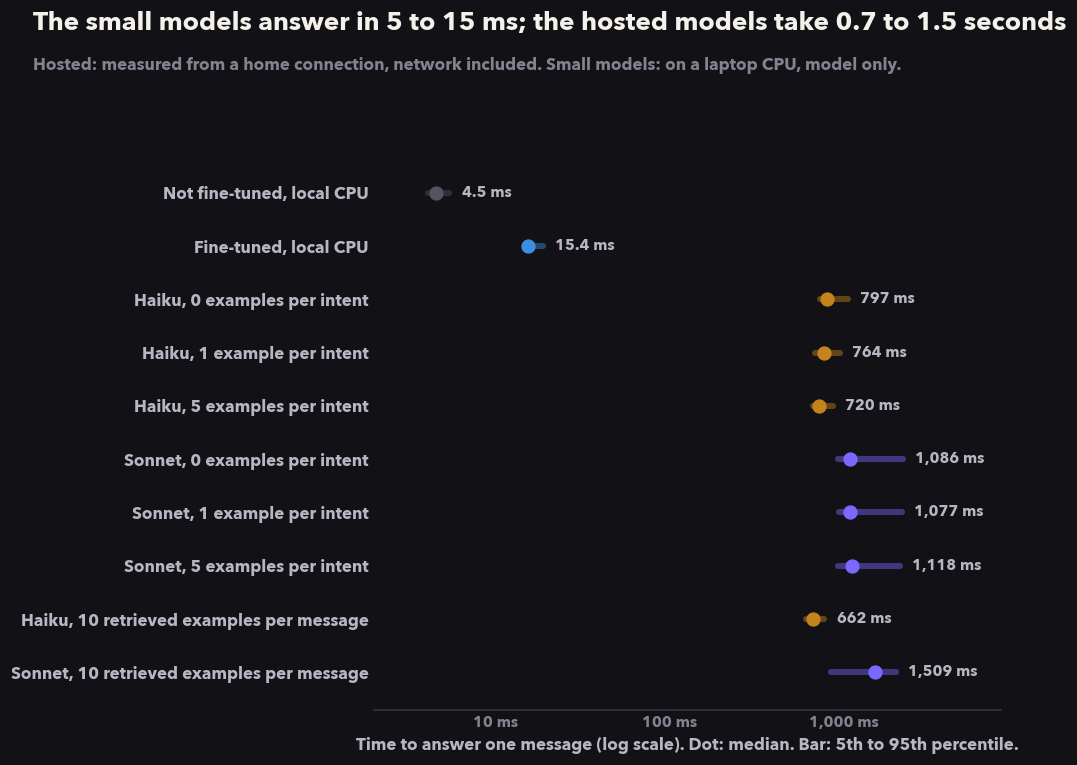

In [7]:
lat = []
for approach in ["frozen", "finetuned"]:
    ms = local_ms.loc[local_ms["approach"] == approach, "ms"]
    lat.append({"label": {"frozen": "Not fine-tuned, local CPU", "finetuned": "Fine-tuned, local CPU"}[approach], "ms": ms, "colour": style.APPROACH_COLORS[approach]})
for run, df in records.items():
    lat.append({"label": name(run), "ms": df["latency_s"] * 1000,
                "colour": style.APPROACH_COLORS[df["model_key"].iloc[0]]})
lat = pd.DataFrame([{"label": d["label"], "value": d["ms"].median(), "low": d["ms"].quantile(0.05),
                     "high": d["ms"].quantile(0.95), "colour": d["colour"]} for d in lat])

fig, ax = plots.dot_intervals(lat, value_format=lambda v: f"{v:,.0f} ms" if v >= 100 else f"{v:.1f} ms", zero_line=False)
ax.set_xscale("log")
ax.set_xticks([1, 10, 100, 1000, 10000])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f} ms"))
ax.minorticks_off()
ax.set_xlim(2, 8000)
ax.set_xlabel("Time to answer one message (log scale). Dot: median. Bar: 5th to 95th percentile.")
fig.subplots_adjust(top=0.80, left=0.33)
local_max, api = lat["value"].iloc[1], lat["value"].iloc[2:]
style.headline(fig, f"The small models answer in {lat['value'].iloc[0]:.0f} to {local_max:.0f} ms; "
                    f"the hosted models take {api.min() / 1000:.1f} to {api.max() / 1000:.1f} seconds",
               "Hosted: measured from a home connection, network included. Small models: on a laptop CPU, model only.")
style.save(fig, "latency")
lat[["label", "value", "low", "high"]].set_index("label").rename_axis("Option").rename(
    columns={"value": "Median (ms)", "low": "5th percentile (ms)", "high": "95th percentile (ms)"}).style.format("{:,.1f}")

A second is fine for routing a support message to a queue, but too slow for a step that runs on every keystroke or many times per user action. Longer cached prompts barely slow the hosted models down, because the cached part does not have to be processed again. Sonnet with retrieved examples is the slowest, at about one and a half seconds, and finding the similar examples adds the embedding model's few milliseconds on top.

## 5. Cost against accuracy

Each hosted option is a point: its measured cost per 1,000 requests, and its accuracy on the 1,540 test messages that every option answered. The self-hosted models are a line, because their cost per request falls as volume rises: the line runs from 100,000 requests a month (right end) to 10 million (left end), with a mark at a million.

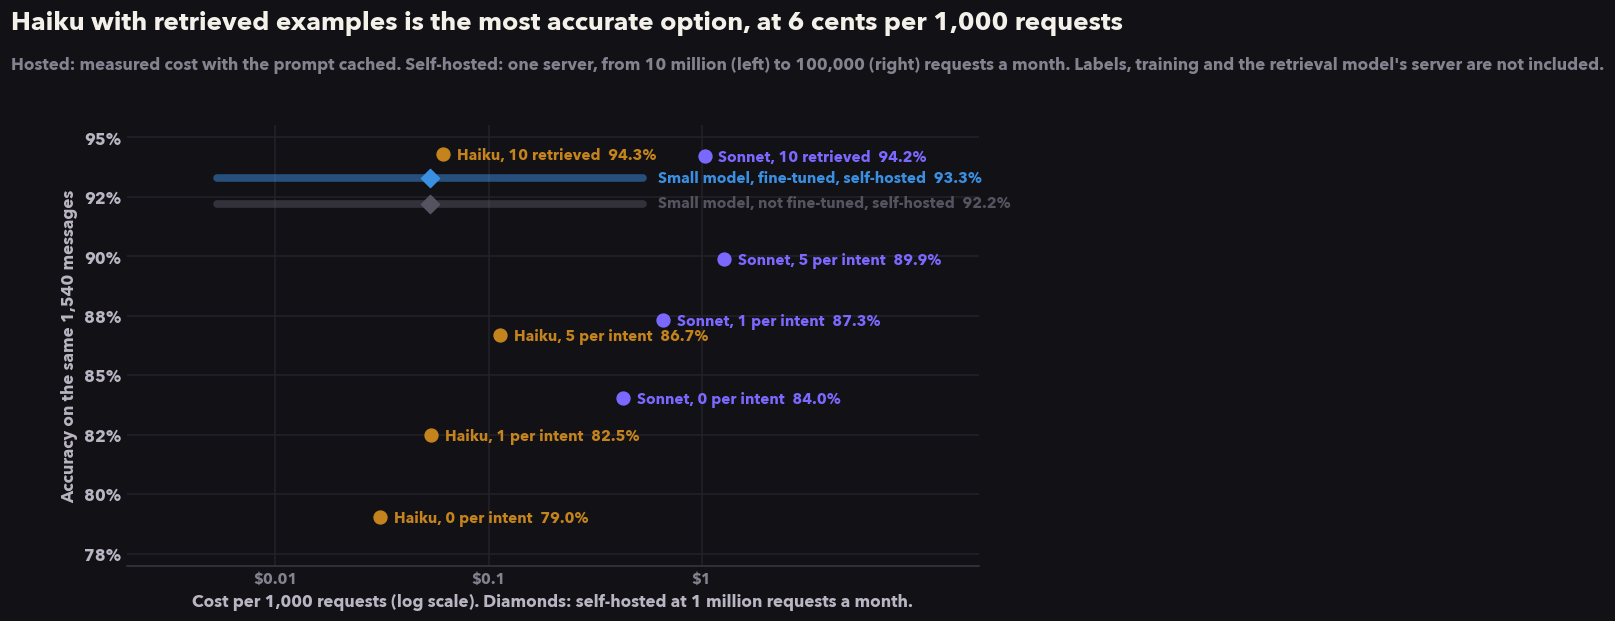

In [8]:
rows = correctness("sonnet", 5).index
points = pd.DataFrame({
    "label": [name(run).replace(" examples per intent", " per intent").replace(" example per intent", " per intent")
              .replace(" retrieved examples per message", " retrieved") for run in runs.index],
    "cost": cost["With caching (as run)"].to_numpy(),
    "accuracy": [correctness(*approach_and_size(run)).loc[rows].mean() for run in runs.index],
    "colour": [style.APPROACH_COLORS[run.split("_")[0]] for run in runs.index],
})
local = {"frozen": correctness("frozen", "all").loc[rows].mean(),
         "finetuned": correctness("finetuned", "all", seeds=(0, 1, 2)).loc[rows].mean()}
at = lambda v: 1000 * server / v

fig, ax = plt.subplots(figsize=(10, 5.8))
for approach, acc in local.items():
    colour = style.APPROACH_COLORS[approach]
    ax.plot([at(10_000_000), at(100_000)], [acc, acc], color=colour, linewidth=5, alpha=0.5, solid_capstyle="round")
    ax.scatter(at(1_000_000), acc, color=colour, s=70, zorder=3, marker="D")
    ax.annotate(f"{style.APPROACH_LABELS[approach]}, self-hosted  {acc:.1%}", (at(100_000), acc), xytext=(10, 0),
                textcoords="offset points", va="center", color=colour, fontsize=10, fontweight="bold")
for r in points.itertuples():
    ax.scatter(r.cost, r.accuracy, color=r.colour, s=70, zorder=3)
    ax.annotate(f"{r.label}  {r.accuracy:.1%}", (r.cost, r.accuracy), xytext=(9, -1), textcoords="offset points",
                va="center", color=r.colour, fontsize=10)
ax.set_xscale("log")
ax.set_xticks([0.001, 0.01, 0.1, 1])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:g}"))
ax.minorticks_off()
ax.set_xlim(0.002, 20)
ax.set_ylim(0.77, 0.955)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Cost per 1,000 requests (log scale). Diamonds: self-hosted at 1 million requests a month.")
ax.set_ylabel("Accuracy on the same 1,540 messages")
ax.grid(axis="y")
fig.subplots_adjust(top=0.80)
best = points.loc[points["accuracy"].idxmax()]
style.headline(fig, f"{best['label'].split(',')[0]} with retrieved examples is the most accurate option, "
                    f"at {best['cost'] * 100:.0f} cents per 1,000 requests",
               "Hosted: measured cost with the prompt cached. Self-hosted: one server, from 10 million (left) to 100,000 (right) "
               "requests a month. Labels, training and the retrieval model's server are not included.")
style.save(fig, "cost_vs_accuracy")

## What this means

- **Cache the prompt.** For a classifier with a long, fixed list of options, caching cuts the hosted bill by 85% to 94% when the examples are fixed. Without it, putting examples in the prompt would be far too expensive.
- **Examples chosen for each message beat examples chosen in advance, and cost less.** Haiku with 10 retrieved examples is the most accurate option in the study, at about 6 cents per 1,000 requests, half the price of Haiku with five fixed examples of every intent. But it needs all the labels and a small embedding model running somewhere, so it shares much of the self-hosted option's fixed cost (notebook 05).
- **Self-hosting is a fixed cost, so volume decides.** At a million requests a month one small server costs about as much per request as Haiku with fixed examples; above about two million it is cheaper than any prompt.
- **The small models are about 50 to 250 times faster.** Milliseconds against about a second, which matters if the classifier sits inside an interactive step.

**What the data can't tell us.** The server price is on-demand and leaves out the engineering time to deploy and maintain a model, which can easily outweigh \$53 a month; notebook 05 adds labelling, training and upkeep. Hosted speeds were measured from one connection over a short period, and both prices and speeds change. The hosted costs depend on the prompt: a shorter label list, or asking for the intent number instead of a JSON object, would cost less.